# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

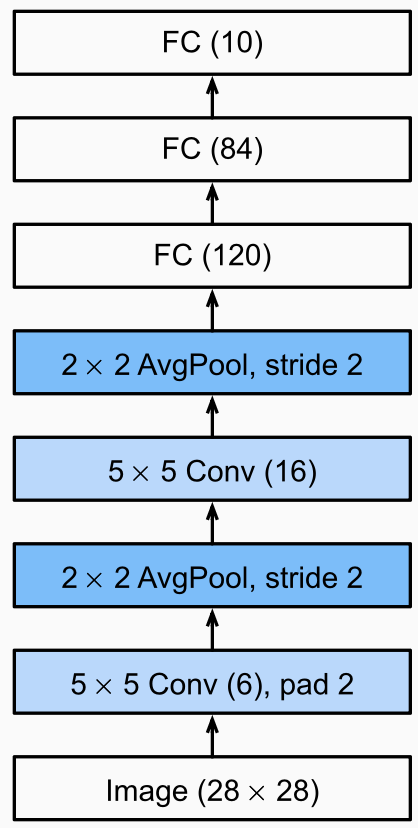

In [1]:
# Import libs
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Device runtime
print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.14.1+cu126
device : cuda


In [2]:
# Config and import VinaFood21
from pathlib import Path

# Config
DATA_ROOT = Path("VinaFood21")
IMG_SIZE = 64
BATCH = 32
SEED = 42
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# Tranform data
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Import data
train_ds = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
val_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
train_dl = DataLoader(train_ds,batch_size=BATCH,shuffle=True,num_workers=2)
val_dl = DataLoader(val_ds,batch_size=BATCH,shuffle=False,num_workers=2)
CLASSES = train_ds.classes

In [3]:
#Init params count function
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)

#Init layer params count function
def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img, device=next(model.parameters()).device)
    rows, total = [], 0
    for name, layer in [("Conv1", model.conv1), ("Pool1", model.pool1),
                        ("Conv2", model.conv2), ("Pool2", model.pool2)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("Dense1", model.dense1), ("Dense2", model.dense2), ("OUT", model.out)]:
        x = layer(x)
        p = n_params(layer)
        total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total

# Init training and eval functions
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

In [4]:
class LeNet_original(nn.Module):
    def __init__(self, in_channel, img_size, num_classes):
        super().__init__()
        Pool = nn.AvgPool2d
        self.conv1 = nn.Conv2d(in_channels=in_channel, out_channels=6, kernel_size=5, padding=2)
        self.pool1 = Pool(kernel_size=2 , stride=2)
        self.conv2 = nn.Conv2d(in_channels=6,out_channels=16, kernel_size=5)
        self.pool2 = Pool(kernel_size=2, stride=2)
        flatten_length = self._flat_dim(in_channel,img_size)
        
        self.dense1 = nn.Linear(flatten_length,120)
        self.dense2 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def _flat_dim(self, in_channel, img_size):
        with torch.no_grad():
            flat = torch.zeros(1, in_channel, img_size, img_size)
            #forward pass getting dim
            flat = self.pool2(self.conv2(self.pool1(self.conv1(flat))))
        return int(flat.flatten(1).shape[1])

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)
        x = x.flatten(1)
        x = torch.relu(self.dense1(x))
        x = torch.relu(self.dense2(x))
        return self.out(x)

class LeNet_edited(nn.Module):
    def __init__(self, in_channel, img_size, num_classes):
        super().__init__()
        Pool = nn.MaxPool2d
        self.conv1 = nn.Conv2d(in_channels=in_channel, out_channels=6, kernel_size=5, padding=2)
        self.pool1 = Pool(kernel_size=2 , stride=2)
        self.conv2 = nn.Conv2d(in_channels=6,out_channels=16, kernel_size=5)
        self.pool2 = Pool(kernel_size=2, stride=2)
        flatten_length = self._flat_dim(in_channel,img_size)
        
        self.dense1 = nn.Linear(flatten_length,120)
        self.dense2 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)

    def _flat_dim(self, in_channel, img_size):
        with torch.no_grad():
            flat = torch.zeros(1, in_channel, img_size, img_size)
            #forward pass getting dim
            flat = self.pool2(self.conv2(self.pool1(self.conv1(flat))))
        return int(flat.flatten(1).shape[1])

    def forward(self, x):
        x = torch.relu(self.conv1(x))
        x = self.pool1(x)
        x = torch.relu(self.conv2(x))
        x = self.pool2(x)
        x = x.flatten(1)
        x = torch.relu(self.dense1(x))
        x = torch.relu(self.dense2(x))
        return self.out(x)

In [5]:
# Init original model ande edited to MaxPool
lenet = LeNet_original(in_channel=3, img_size=IMG_SIZE, num_classes=21).to(device)
print("lenet")
print("params:", f"{n_params(lenet):,}")

print(f"{'layer':<10}{'output':<16}{'params':>12}")
rows, total = layer_table(lenet, IMG_SIZE)
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")

print(f"{'sum':<10}{'':<16}{total:>12,}")

print("\nlenet edited")
# Lenet edit
lenet_edit = LeNet_edited(in_channel=3, img_size=IMG_SIZE, num_classes=21).to(device)
print("params:", f"{n_params(lenet_edit):,}")

print(f"{'layer':<10}{'output':<16}{'params':>12}")
rows, total = layer_table(lenet_edit, IMG_SIZE)
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")

print(f"{'sum':<10}{'':<16}{total:>12,}")


lenet
params: 391,261
layer     output                params
Conv1     6x64x64                  456
Pool1     6x32x32                    0
Conv2     16x28x28               2,416
Pool2     16x14x14                   0
flatten   3136                       0
Dense1    120                  376,440
Dense2    84                    10,164
OUT       21                     1,785
sum                            391,261

lenet edited
params: 391,261
layer     output                params
Conv1     6x64x64                  456
Pool1     6x32x32                    0
Conv2     16x28x28               2,416
Pool2     16x14x14                   0
flatten   3136                       0
Dense1    120                  376,440
Dense2    84                    10,164
OUT       21                     1,785
sum                            391,261


In [6]:
#Training
import time

model = lenet.to(device)

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_lenet = []
times = []

for ep in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    epoch_time = time.perf_counter() - start
    times.append(epoch_time)

    val_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_lenet.append((ep, train_loss, val_loss))

    print(f"epoch {ep:>2} train {train_loss:.4f}/{tr_acc:.4f}"
          f" val {val_loss:.4f}/{va_acc:.4f}"
          f" time {epoch_time:.2f}s")

/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1 train 2.7743/0.1528 val 2.6000/0.2145 time 47.10s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2 train 2.5502/0.2223 val 2.5452/0.2275 time 47.31s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 train 1.8755/0.4137 val 2.2781/0.3212 time 44.00s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 train 1.8542/0.4302 val 2.2582/0.3174 time 43.97s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 train 1.8449/0.4288 val 2.3256/0.3129 time 43.76s


In [7]:
#Training
model = lenet_edit.to(device)

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_lenet_edit = []
times = []

for ep in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    epoch_time = time.perf_counter() - start
    times.append(epoch_time)

    val_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_lenet_edit.append((ep, train_loss, val_loss))

    print(f"epoch {ep:>2} train {train_loss:.4f}/{tr_acc:.4f}"
          f" val {val_loss:.4f}/{va_acc:.4f}"
          f" time {epoch_time:.2f}s")

/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1 train 2.8335/0.1468 val 2.6950/0.1797 time 44.56s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2 train 2.6226/0.2030 val 2.5631/0.2128 time 45.04s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 train 1.8731/0.4122 val 2.1987/0.3325 time 42.37s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 train 1.8619/0.4159 val 2.1698/0.3367 time 42.77s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 train 1.8398/0.4271 val 2.2071/0.3219 time 43.47s


Macro-F1 Orginal LeNet:  0.2834311527829375
Accuracy Orignal LeNet:  0.3129302604010775
                  precision    recall  f1-score   support

        banh-can     0.2286    0.1992    0.2129       241
        banh-hoi     0.3560    0.4481    0.3968       607
    banh-mi-chao     0.3344    0.3460    0.3401       289
        banh-tet     0.4234    0.1291    0.1979       364
 banh-trang-tron     0.1636    0.0583    0.0859       309
          banh-u     0.2941    0.2273    0.2564       176
        banh-uot     0.2733    0.4393    0.3370       560
       bap-nuong     0.1489    0.0490    0.0737       143
          bo-kho     0.2331    0.5296    0.3237       338
       bo-la-lot     0.4283    0.5349    0.4757       458
       bot-chien     0.2140    0.1993    0.2064       276
           ca-ri     0.2500    0.0526    0.0870       171
    canh-kho-qua     0.4983    0.5069    0.5026       290
   canh-khoai-mo     0.7447    0.7071    0.7254       198
        ga-nuong     0.3239    0.1532    

<Axes: >

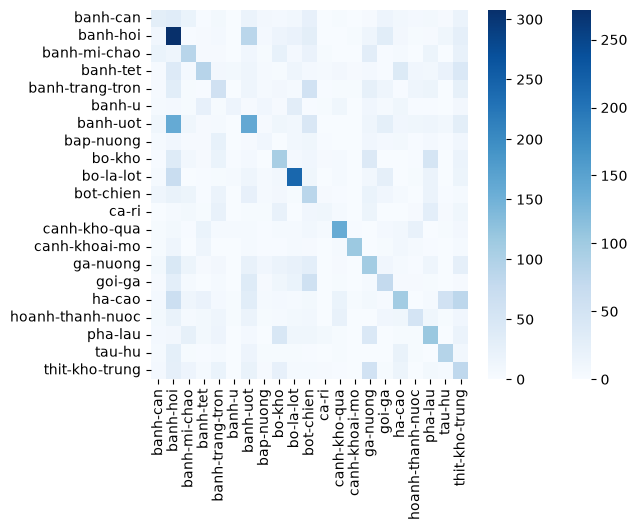

In [8]:
from sklearn.metrics import f1_score, accuracy_score,confusion_matrix, classification_report
import seaborn as sns
#Evals
_, _, y_true_lenet, y_pred_lenet = evaluate(lenet, val_dl, criterion, device)
print('Macro-F1 Orginal LeNet: ', f1_score(y_true_lenet, y_pred_lenet, average="macro"))
print('Accuracy Orignal LeNet: ', accuracy_score(y_true_lenet, y_pred_lenet))
print(classification_report(y_true_lenet, y_pred_lenet, target_names=CLASSES, digits=4))
sns.heatmap(confusion_matrix(y_true_lenet, y_pred_lenet), xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")

_, _, y_true_lenet_edit, y_pred_lenet_edit = evaluate(lenet_edit, val_dl, criterion, device)
print('\nMacro-F1 Edited LeNet: ', f1_score(y_true_lenet_edit, y_pred_lenet_edit, average="macro"))
print('Accuracy Edited LeNet: ', accuracy_score(y_true_lenet_edit, y_pred_lenet_edit))
print("Confusion matrix: ",confusion_matrix(y_true_lenet_edit, y_pred_lenet_edit))
print(classification_report(y_true_lenet_edit, y_pred_lenet_edit, target_names=CLASSES, digits=4))
sns.heatmap(confusion_matrix(y_true_lenet_edit, y_pred_lenet_edit), xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**

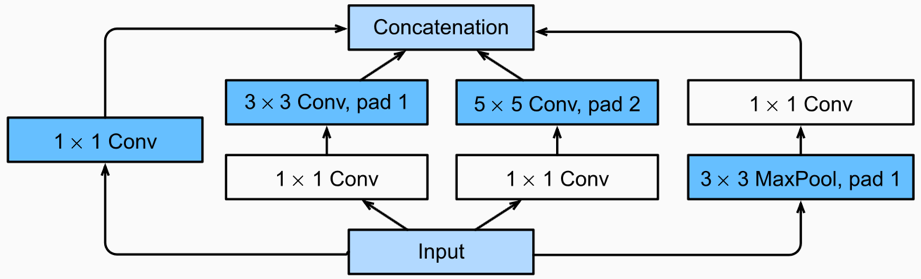

**GoogLeNet (Multi-branch Network)**

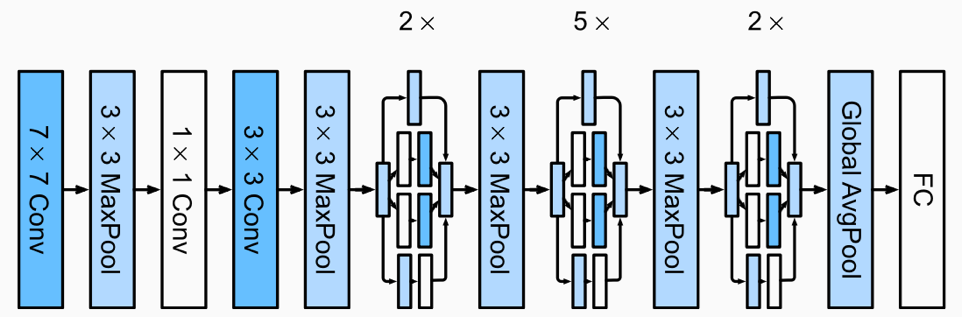

In [9]:
#Init get block shape and parameters count
def inspect_blocks(model, input_shape=(32, 3, 64, 64)):
    x = torch.randn(*input_shape).to(next(model.parameters()).device)
    names = ["block1", "block2", "block3", "adaptive_pool", "flat", "linear"]

    model.eval()
    with torch.no_grad():
        print(f"{'layer':<16}{'output':<20}{'params':>12}")
        print(f"{'Input':<16}{str(tuple(x.shape)):<20}{0:>12,}")

        for i, layer in enumerate(model):
            x = layer(x)
            print(f"{names[i]:<16}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")

In [10]:
class InceptionBlock(nn.Module):
    def __init__(self, in_channels, filter1, filter3r, filter3, filter5r, filter5, filterp):
        super().__init__()
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels,filter1,1),nn.ReLU()
        )

        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels,filter3r,1),nn.ReLU(),
            nn.Conv2d(filter3r,filter3,3,padding=1),nn.ReLU()
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels,filter5r,1),nn.ReLU(),
            nn.Conv2d(filter5r,filter5,5,padding=2),nn.ReLU()
        )

        self.branch4 = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1,padding=1),
            nn.Conv2d(in_channels,filterp,1),nn.ReLU()
        )

    def forward(self, x):
        return torch.cat([self.branch1(x),self.branch2(x),
                        self.branch3(x),self.branch4(x)],dim=1)

In [11]:
#Multi-branch network init
#Input (32,3,64,64)
#16+32+8+8=64 Output channels
#Output (32,64,32,32) after Pool
block1 = nn.Sequential(InceptionBlock(3,16,8,32,4,8,8),nn.AvgPool2d(kernel_size=2, stride=2))

#Input (32,64,32,32)
#32+64+16+16=128 Output channels
#Output (32,128,16,16) after Pool
block2 = nn.Sequential(InceptionBlock(64,32,16,64,8,16,16),nn.AvgPool2d(kernel_size=2, stride=2))

#Input (32,128,16,16)
#64+128+32+32=256 Output channels
#Output (32,256,8,8) after Pool
block3 = nn.Sequential(InceptionBlock(128,64,32,128,16,32,32),nn.AvgPool2d(kernel_size=2, stride=2))

multi_branch_network = nn.Sequential(
    block1,
    block2,
    block3,
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(256, 21)
)

inspect_blocks(
    multi_branch_network,
    input_shape=(BATCH, 3, IMG_SIZE, IMG_SIZE)
)

print("params:", f"{n_params(multi_branch_network):,}")

layer           output                    params
Input           (32, 3, 64, 64)                0
block1          (32, 64, 32, 32)           3,288
block2          (32, 128, 16, 16)         17,176
block3          (32, 256, 8, 8)           68,400
adaptive_pool   (32, 256, 1, 1)                0
flat            (32, 256)                      0
linear          (32, 21)                   5,397
params: 94,261


In [12]:
#Training
model = multi_branch_network.to(device)

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_googlenet = []
times = []

for ep in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    epoch_time = time.perf_counter() - start
    times.append(epoch_time)

    val_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_googlenet.append((ep, train_loss, val_loss))

    print(f"epoch {ep:>2} train {train_loss:.4f}/{tr_acc:.4f}"
          f" val {val_loss:.4f}/{va_acc:.4f}"
          f" time {epoch_time:.2f}s")

/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1 train 2.8482/0.1305 val 2.7670/0.1544 time 44.88s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2 train 2.6198/0.1915 val 2.6002/0.2041 time 44.44s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 train 1.8443/0.4201 val 2.0778/0.3741 time 50.93s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 train 1.8178/0.4354 val 2.0991/0.3635 time 50.64s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 train 1.8054/0.4358 val 2.0385/0.3771 time 49.47s


Macro-F1 Inception Blocks:  0.35513361795137677
Accuracy Inception Blocks:  0.3771325950314277
                  precision    recall  f1-score   support

        banh-can     0.2685    0.2407    0.2538       241
        banh-hoi     0.5634    0.4465    0.4982       607
    banh-mi-chao     0.3118    0.5502    0.3980       289
        banh-tet     0.3017    0.4286    0.3541       364
 banh-trang-tron     0.2895    0.0712    0.1143       309
          banh-u     0.3204    0.3295    0.3249       176
        banh-uot     0.3576    0.3946    0.3752       560
       bap-nuong     0.2545    0.1958    0.2213       143
          bo-kho     0.3802    0.4320    0.4044       338
       bo-la-lot     0.6247    0.6070    0.6157       458
       bot-chien     0.3149    0.3913    0.3489       276
           ca-ri     0.2771    0.1345    0.1811       171
    canh-kho-qua     0.3806    0.7034    0.4939       290
   canh-khoai-mo     0.8272    0.6768    0.7444       198
        ga-nuong     0.3253    0.2

<Axes: >

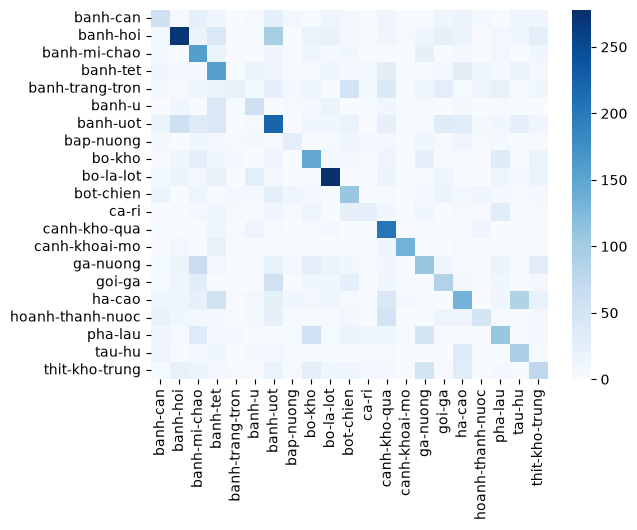

In [13]:
#Evals
_, _, y_true_googlenet, y_pred_googlenet = evaluate(multi_branch_network, val_dl, criterion, device)
print('Macro-F1 Inception Blocks: ', f1_score(y_true_googlenet, y_pred_googlenet, average="macro"))
print('Accuracy Inception Blocks: ', accuracy_score(y_true_googlenet, y_pred_googlenet))
print(classification_report(y_true_googlenet, y_pred_googlenet, target_names=CLASSES, digits=4))
sns.heatmap(confusion_matrix(y_true_googlenet, y_pred_googlenet), xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**

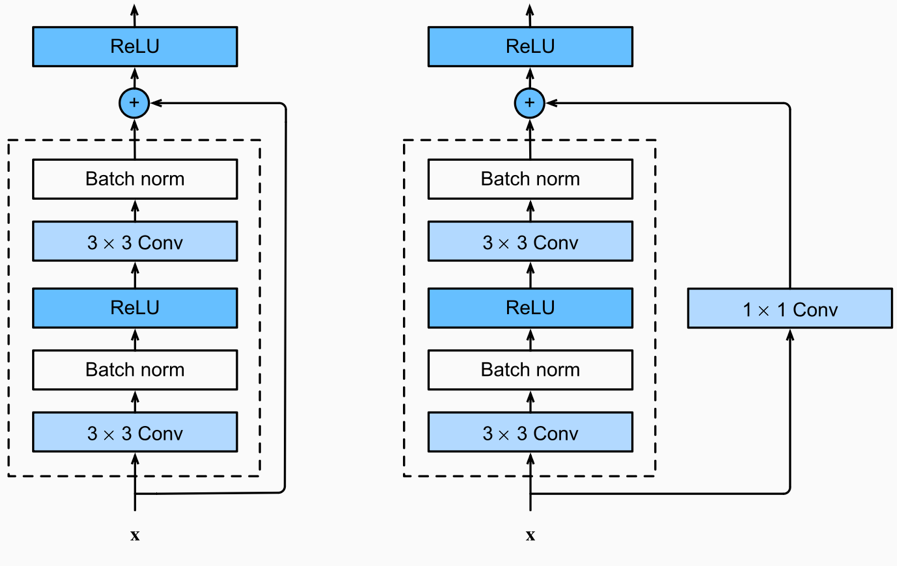

**ResNet**

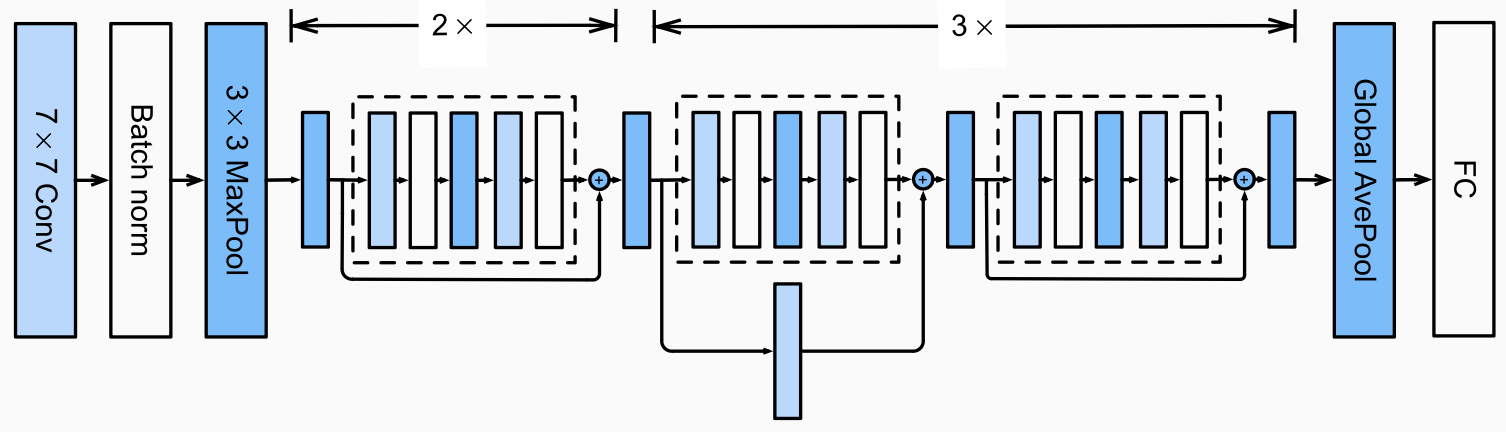

In [14]:
# New IMG_SIZE
IMG_SIZE = 112

# Tranform data
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Re-import data with new transform
train_ds = datasets.ImageFolder(DATA_ROOT / "train", transform=train_tf)
val_ds = datasets.ImageFolder(DATA_ROOT / "test", transform=eval_tf)
train_dl = DataLoader(train_ds,batch_size=BATCH,shuffle=True,num_workers=2)
val_dl = DataLoader(val_ds,batch_size=BATCH,shuffle=False,num_workers=2)

In [15]:
class BasicBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels,out_channels, 3, stride, padding=1, bias=False)
        self.batch_norm1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, 1, padding=1, bias=False)
        self.batch_norm2 = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Identity()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = torch.relu(self.batch_norm1(self.conv1(x)))
        out = self.batch_norm2(self.conv2(out))
        out = out + self.shortcut(x)
        return torch.relu(out)

class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_channels, out_channels, stride):
        return nn.Sequential(BasicBlock(in_channels,out_channels,stride),
                             BasicBlock(out_channels,out_channels,1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1,self.layer2,self.layer3,self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))

In [16]:
#Init Resnet-18
resnet = ResNet18()
x = torch.rand(BATCH, 3, IMG_SIZE, IMG_SIZE)

print(f"{'stage':<12}{'output shape':<20}{'tham số':>12}")
x = resnet.stem(x)
print(f"{'stem':<12}{str(tuple(x.shape)):<20}{n_params(resnet.stem):>12,}")
for name in ("layer1", "layer2", "layer3", "layer4"):
    layer = getattr(resnet, name)
    x = layer(x)
    print(f"{name:<12}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")
v = resnet.pool(x).flatten(1)
print(f"{'avgpool':<12}{str(tuple(v.shape)):<20}{0:>12,}")
print(f"{'fc':<12}{str(tuple(resnet.fc(v).shape)):<20}{n_params(resnet.fc):>12,}")
print("params:", f"{n_params(resnet):,}")

stage       output shape             tham số
stem        (32, 64, 28, 28)           9,536
layer1      (32, 64, 28, 28)         147,968
layer2      (32, 128, 14, 14)        525,568
layer3      (32, 256, 7, 7)        2,099,712
layer4      (32, 512, 4, 4)        8,393,728
avgpool     (32, 512)                      0
fc          (32, 21)                  10,773
params: 11,187,285


In [17]:
#Training
model = resnet.to(device)

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_resnet = []
times = []

for ep in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, tr_acc = train_one_epoch(
        model, train_dl, criterion, optimizer, device
    )
    epoch_time = time.perf_counter() - start
    times.append(epoch_time)

    val_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_resnet.append((ep, train_loss, val_loss))

    print(f"epoch {ep:>2} train {train_loss:.4f}/{tr_acc:.4f}"
          f" val {val_loss:.4f}/{va_acc:.4f}"
          f" time {epoch_time:.2f}s")

/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1 train 2.7134/0.1883 val 2.6457/0.2056 time 49.71s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2 train 2.4240/0.2547 val 2.5101/0.2490 time 49.69s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 train 1.1588/0.6297 val 1.6223/0.5304 time 49.67s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 train 1.1044/0.6439 val 1.6777/0.5175 time 49.05s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 train 1.0452/0.6641 val 1.6576/0.5160 time 50.19s


Macro-F1 ResNet18:  0.5025343955013958
Accuracy ResNet18:  0.5160131697096678
                  precision    recall  f1-score   support

        banh-can     0.6259    0.3610    0.4579       241
        banh-hoi     0.4849    0.7150    0.5779       607
    banh-mi-chao     0.6738    0.5433    0.6015       289
        banh-tet     0.8049    0.4533    0.5800       364
 banh-trang-tron     0.3497    0.3236    0.3361       309
          banh-u     0.3550    0.4659    0.4029       176
        banh-uot     0.5197    0.3304    0.4039       560
       bap-nuong     0.3904    0.3986    0.3945       143
          bo-kho     0.5504    0.4527    0.4968       338
       bo-la-lot     0.7072    0.6856    0.6962       458
       bot-chien     0.6116    0.5362    0.5714       276
           ca-ri     0.3590    0.1637    0.2249       171
    canh-kho-qua     0.5086    0.8138    0.6260       290
   canh-khoai-mo     0.9272    0.7071    0.8023       198
        ga-nuong     0.5040    0.3360    0.4032    

<Axes: >

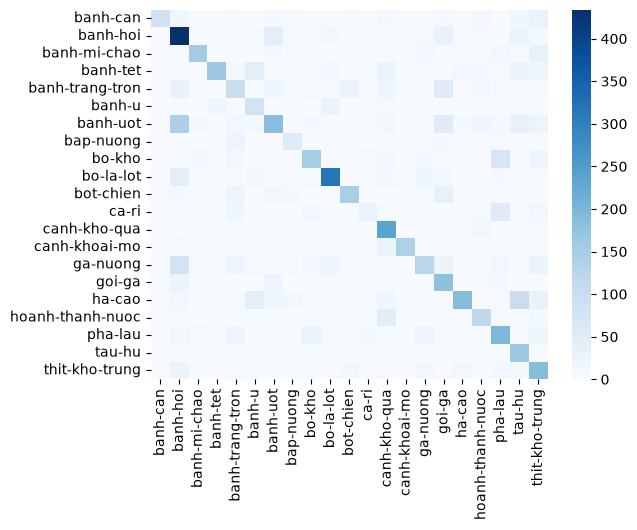

In [18]:
_, _, y_true_resnet, y_pred_resnet = evaluate(resnet, val_dl, criterion, device)
print('Macro-F1 ResNet18: ', f1_score(y_true_resnet, y_pred_resnet, average="macro"))
print('Accuracy ResNet18: ', accuracy_score(y_true_resnet, y_pred_resnet))
print(classification_report(y_true_resnet, y_pred_resnet, target_names=CLASSES, digits=4))
sns.heatmap(confusion_matrix(y_true_resnet, y_pred_resnet), xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")

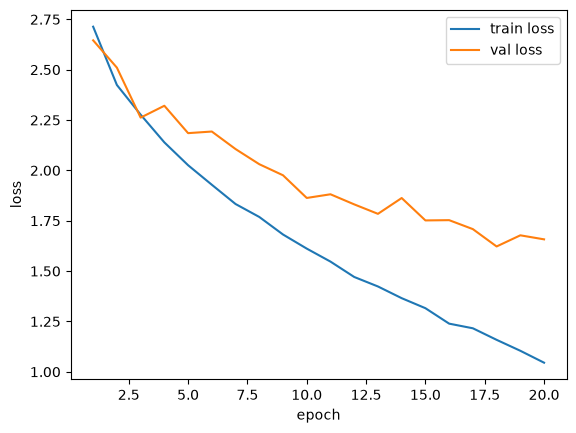

In [19]:
import matplotlib.pyplot as plt
#Train val loss over epochs
ep, tr, va = zip(*lich_su_resnet)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [20]:
#Training second model, no augmentation
train_ds_noaug = datasets.ImageFolder(DATA_ROOT / "train", transform=eval_tf)
train_dl_noaug = DataLoader(train_ds_noaug,batch_size=BATCH,shuffle=True,num_workers=2)

resnet_noaug = ResNet18().to(device)
model = resnet_noaug

EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

lich_su_resnet_noaug = []
times = []

for ep in range(1, EPOCHS + 1):
    start = time.perf_counter()

    train_loss, tr_acc = train_one_epoch(
        model, train_dl_noaug, criterion, optimizer, device
    )
    epoch_time = time.perf_counter() - start
    times.append(epoch_time)

    val_loss, va_acc, _, _ = evaluate(
        model, val_dl, criterion, device
    )

    lich_su_resnet_noaug.append((ep, train_loss, val_loss))

    print(f"epoch {ep:>2} train {train_loss:.4f}/{tr_acc:.4f}"
          f" val {val_loss:.4f}/{va_acc:.4f}"
          f" time {epoch_time:.2f}s")


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  1 train 2.6173/0.2083 val 3.0996/0.1832 time 47.15s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch  2 train 2.3026/0.2845 val 2.5751/0.2369 time 48.56s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


...

epoch 18 train 0.1470/0.9513 val 3.0056/0.4330 time 46.99s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 19 train 0.0937/0.9712 val 3.2477/0.4386 time 46.92s


/home/ngt/Documents/5th-semester/DS201/lab/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


epoch 20 train 0.1023/0.9670 val 3.3353/0.4340 time 46.40s


Macro-F1 ResNet18 no-aug:  0.426011699102852
Accuracy ResNet18 no-aug:  0.43400179586950016
                  precision    recall  f1-score   support

        banh-can     0.3552    0.2697    0.3066       241
        banh-hoi     0.4885    0.4217    0.4527       607
    banh-mi-chao     0.6265    0.3599    0.4571       289
        banh-tet     0.6465    0.3516    0.4555       364
 banh-trang-tron     0.4043    0.1845    0.2533       309
          banh-u     0.3967    0.2727    0.3232       176
        banh-uot     0.3378    0.4946    0.4014       560
       bap-nuong     0.2920    0.2797    0.2857       143
          bo-kho     0.4921    0.3669    0.4203       338
       bo-la-lot     0.6169    0.6223    0.6196       458
       bot-chien     0.3145    0.4638    0.3748       276
           ca-ri     0.2893    0.2690    0.2788       171
    canh-kho-qua     0.5110    0.4000    0.4487       290
   canh-khoai-mo     0.8537    0.7071    0.7735       198
        ga-nuong     0.3670    0.4301

<Axes: >

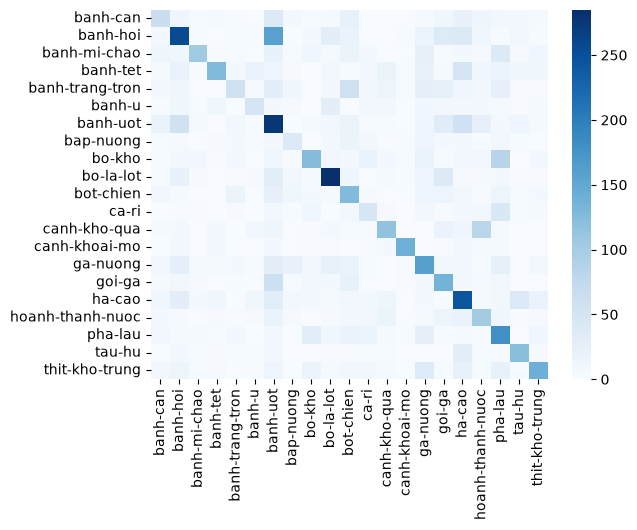

In [21]:
_, _, y_true_resnet_noaug, y_pred_resnet_noaug = evaluate(resnet_noaug, val_dl, criterion, device)
print('Macro-F1 ResNet18 no-aug: ', f1_score(y_true_resnet_noaug, y_pred_resnet_noaug, average="macro"))
print('Accuracy ResNet18 no-aug: ', accuracy_score(y_true_resnet_noaug, y_pred_resnet_noaug))
print(classification_report(y_true_resnet_noaug, y_pred_resnet_noaug, target_names=CLASSES, digits=4))
sns.heatmap(confusion_matrix(y_true_resnet_noaug, y_pred_resnet_noaug), xticklabels=CLASSES, yticklabels=CLASSES, cmap="Blues")


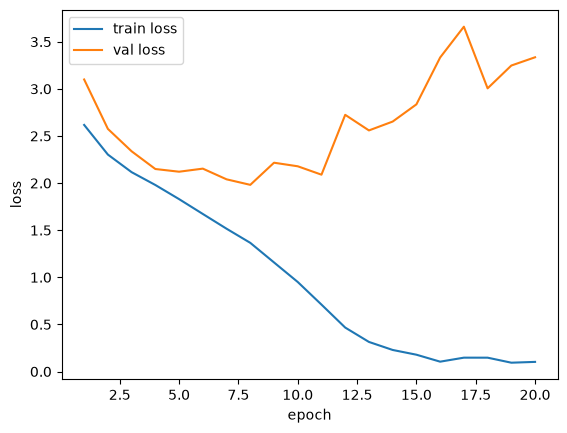

In [22]:
#Train val loss over epochs
ep, tr, va = zip(*lich_su_resnet_noaug)
plt.plot(ep, tr, label="train loss")
plt.plot(ep, va, label="val loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()


### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.